In [39]:
import numpy as np
import matplotlib.pyplot as plt

# list of rules
total_rules = ['111', '110', '101', '100', '011', '010', '001', '000']

In [40]:
# rule translator
def convert_rule_number(number: int):
    str = format(number, f'0{8}b')
    return list(str)
    
# convert_rule_number(150)

def generate_rule_list(rule_number):
    ruled_values = convert_rule_number(rule_number)
    # print(ruled_values)
    assert(len(total_rules) == len(ruled_values))

    # write rules to a dictionary
    rule_dict = {}
    for input, output in zip(total_rules, ruled_values):
        # print(input, output)
        rule_dict[input] = output
    # print(rule_dict)
    return rule_dict

def check_rule_for_position(time, position, matrix):
    out = [0,0,0]
    size = matrix.shape[1]
    out[0] = matrix[time-1, (position-1) % size]
    out[1] = matrix[time-1, position % size]
    out[2] = matrix[time-1, (position+1) % size]
    return f"{out[0]}{out[1]}{out[2]}"

def calculate_value(time, position, matrix, rule_dict):
    rule = check_rule_for_position(time, position, matrix)
    value = int(rule_dict[rule])
    return value

def calculate_value_reverse(time, position, matrix, rule_dict, reverse):
    rule = check_rule_for_position(time, position, matrix)
    value = int(rule_dict[rule])
    if reverse and time >= 2:
        value = (value + matrix[time-2, position]) % 2
    elif reverse:
        value = (value + matrix[time-2, position]) % 2
    return value



In [41]:
import math

def generate_rule_array(rule_number):
    return np.array([int(b) for b in format(rule_number, '08b')])[::-1]

def simulate_CA_fast(time_limit, N, rule_number, reversed=False, n_black=41):

    Matrix = np.zeros((time_limit, N), dtype=np.uint8)

    rule = generate_rule_array(rule_number)

    # initial condition
    start = N//2 - n_black//2
    end = start + n_black

    # 2 rows for reversibility
    Matrix[0, start:end] = 1
    Matrix[1, start:end] = 1

    for t in range(2, time_limit):

        prev = Matrix[t-1]

        left  = np.roll(prev, 1)
        right = np.roll(prev, -1)

        # BINARY ENCODING, a faster version of 
        # index = 4*left + 2*center + right
        pattern = (left << 2) | (prev << 1) | right

        new = rule[pattern]

        if reversed:
            new = (new + Matrix[t-2]) % 2

        Matrix[t] = new

    return Matrix

def coarse_entropy_row(row, m):

    blocks = row[:len(row)//m * m].reshape(-1, m)

    k = blocks.sum(axis=1)

    Nm = np.array([math.comb(m, ki) for ki in k])

    return np.sum(np.log(Nm))

Rules:
{'111': '1', '110': '0', '101': '0', '100': '1', '011': '0', '010': '1', '001': '1', '000': '0'}


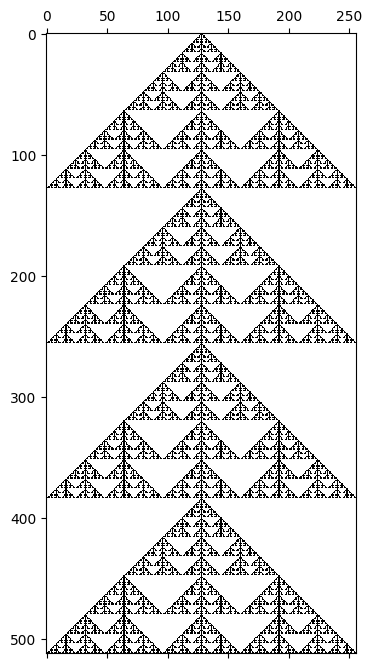

In [42]:
def simulte_cellular_1D(size, start_stop, time_limit, rule_number, reversed=False):
    Matrix = np.zeros((time_limit, size), dtype="int")
    Rule_dict = generate_rule_list(rule_number)
    print(f"Rules:\n{Rule_dict}")
    # first axis is time, second axis is position

    # initialise a state at t = 0
    Matrix[0,start_stop[0]:(start_stop[1]+1)] = 1

    # need to iterate over time
    for time in range(Matrix.shape[0]):
    # for time in [1,2,3,4,5]:
        if time == 0: continue
        # this loop will iterate over all time except 0
        for pos in range(Matrix.shape[1]):
            # compute this for every row
            Matrix[time, pos] = calculate_value_reverse(time, pos, Matrix, Rule_dict, reversed)

    return Matrix

Matrix = simulte_cellular_1D(256, (128,128), 512, 150)
plt.matshow(Matrix, cmap="binary")
# cmap binary is 0 = white, 1 = black

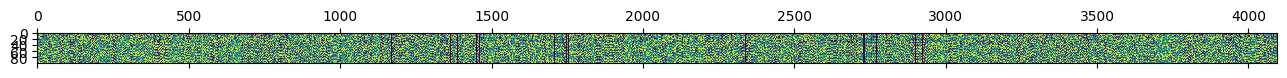

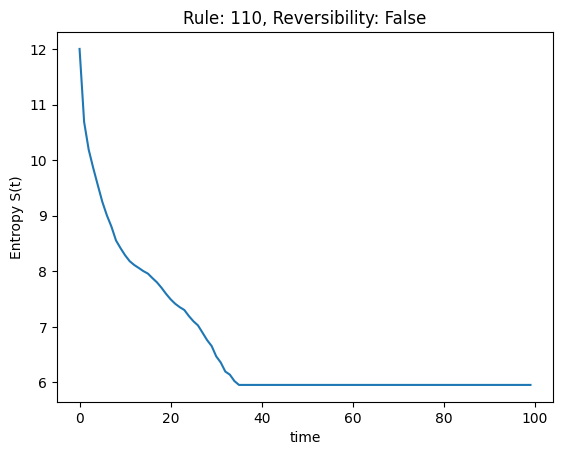

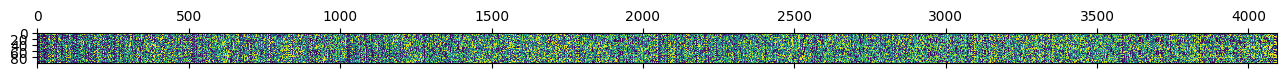

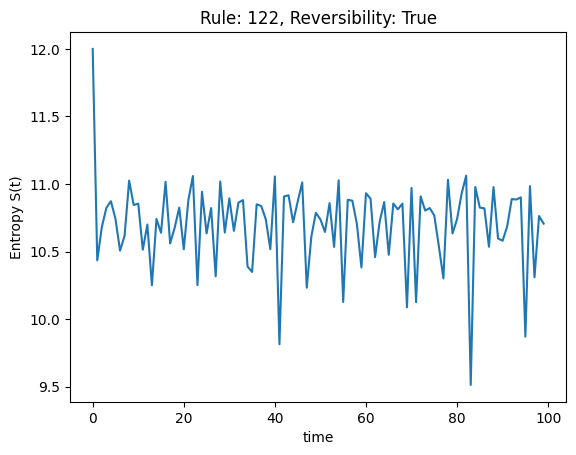

In [43]:
from itertools import product

def generate_initial_conditions(size):
    return [format(i, f'0{size}b') for i in range(2**size)]

def row_to_decimal(row):
    """Convert a binary row (array of 0/1) to a decimal integer."""
    # row is like [1,0,1,0,1,0,0]
    return int("".join(str(b) for b in row), 2)

def simulte_cellular_1D_initial(initial, time_limit, rule_number, reversed=False):
    size = len(initial)
    row = np.array([int(b) for b in initial])
    # print(row)
    Matrix = np.zeros((time_limit, size), dtype="int")
    Rule_dict = generate_rule_list(rule_number)
    # print(f"Rules:\n{Rule_dict}")
    # first axis is time, second axis is position

    # initialise a state at t = 0
    Matrix[0, :] = row

    # need to iterate over time
    for time in range(Matrix.shape[0]):
        if time == 0: continue # the state at time 0 is already set by the initial condition

        for pos in range(Matrix.shape[1]):
            # compute this for every row
            Matrix[time, pos] = calculate_value_reverse(time, pos, Matrix, Rule_dict, reversed)

    evolution = np.array([row_to_decimal(row) for row in Matrix])
    return evolution

from collections import Counter

def row_entropy_Gibbs(row):
    counts = Counter(row)        # count occurrences of each state
    total = len(row)

    probs = np.array(list(counts.values())) / total

    S = -np.sum(probs * np.log2(probs))
    return S

def task2(time_limit, rule_number, number_of_bits, reversed):
    initials = generate_initial_conditions(number_of_bits)

    # pre-allocate the matrix: shape (time, number of initials)
    all_evolutions = np.zeros((time_limit, len(initials)), dtype=int)

    for idx, init in enumerate(initials):
        evolution = simulte_cellular_1D_initial(init, time_limit, rule_number, reversed=reversed)
        all_evolutions[:, idx] = evolution  # assign the evolution column-wise

    # print(all_evolutions.shape)  # should be (50, len(initials))
    plt.matshow(all_evolutions) # time is the y axis, initials is the x axis
    plt.show()

    entropies = []

    for t in range(time_limit):
        row = all_evolutions[t, :]
        S = row_entropy_Gibbs(row)
        entropies.append(S)

    plt.plot(entropies)
    plt.title(f"Rule: {rule_number}, Reversibility: {reversed}")
    plt.xlabel("time")
    plt.ylabel("Entropy S(t)")
    plt.show()

task2(100, 110, 12, False)
task2(100, 122, 12, True)

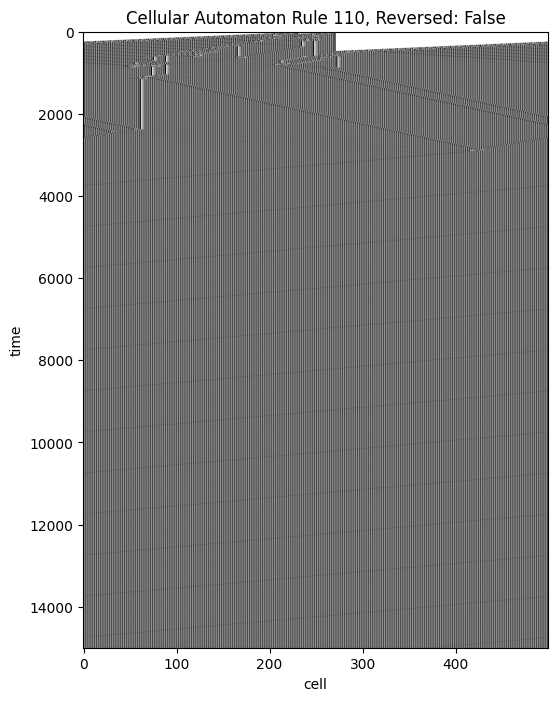

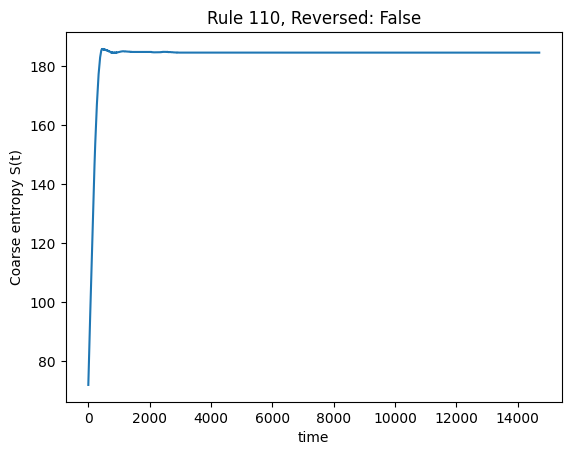

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 1, 1, ..., 0, 1, 0],
       [1, 1, 1, ..., 1, 1, 0],
       [1, 0, 0, ..., 1, 1, 1]], shape=(15000, 500), dtype=uint8)

In [44]:
def task3_fast(time_limit, rule_number, reversed, N=500, n_black=41, m=5, T=300):

    Matrix = simulate_CA_fast(time_limit, N, rule_number, reversed, n_black)

    # plot automata
    plt.figure(figsize=(6,8))
    plt.imshow(Matrix, cmap="binary", aspect="auto")
    plt.xlabel("cell")
    plt.ylabel("time")
    plt.title(f"Cellular Automaton Rule {rule_number}, Reversed: {reversed}")
    plt.show()

    S = []

    # Double nested loop
    # this is quite slow
    for t in range(time_limit - T):

        avg = 0

        for i in range(T):
            avg += coarse_entropy_row(Matrix[t+i], m)

        S.append(avg / T)


    # plot entropy
    plt.plot(S)
    plt.xlabel("time")
    plt.ylabel("Coarse entropy S(t)")
    plt.title(f"Rule {rule_number}, Reversed: {reversed}")
    plt.show()

    return Matrix

task3_fast(
    time_limit=15000,
    rule_number=110,
    reversed=False,
    N=500,
    n_black=41,
    m=5,
    T=300
)

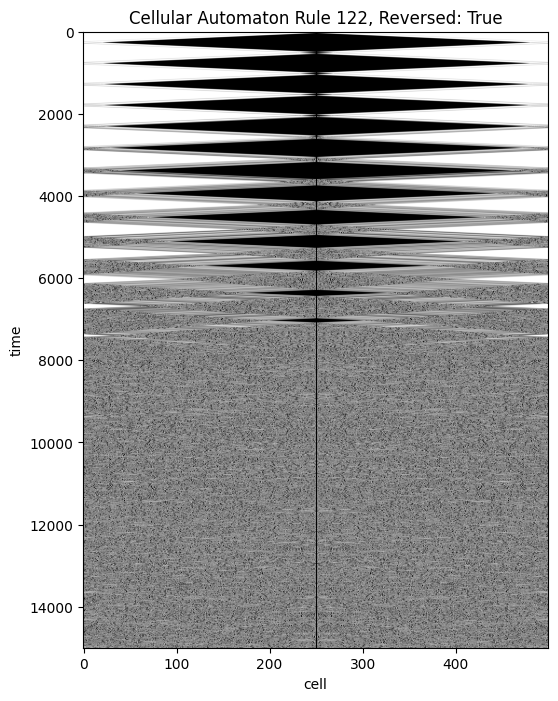

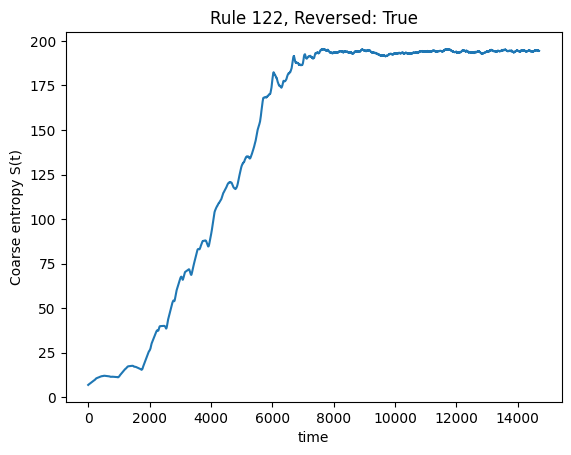

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 1, 0, 0],
       [1, 0, 1, ..., 0, 1, 0],
       [0, 1, 0, ..., 0, 0, 1]], shape=(15000, 500), dtype=uint8)

In [45]:
task3_fast(
    time_limit=15000,
    rule_number=122,
    reversed=True,
    N=500,
    n_black=41,
    m=5,
    T=300
)